# Phenotype, CGM Metrics and the Number of SLH Episodes

Explores which **patient characteristics** (phenotype) and which **CGM metrics** are associated with the number of short-lasting hyperglycaemia (SLH) episodes per patient, using rank-based and information-theoretic measures only (no regression model is fitted):

1. **Spearman correlation** of every continuous variable with n_SLH, and among themselves;
2. **Mutual information** with n_SLH for continuous and categorical variables, with a permutation test;
3. **n_SLH by category** for the categorical phenotype variables.

Equivalent scripts: `python3 -m scripts.statistics.slh_patient_characteristics_exploration` (phenotype) and `python3 -m scripts.statistics.slh_baseline_metrics_multivariate_exploration` (CGM metrics).

**Usage** — from the repository root, point the notebook at a data folder and open it
(the 4-patient synthetic sample is enough: `make sample_data_run`):

```bash
CGM_DATA_ROOT=$PWD/sample_data jupyter lab notebooks/
```

**Data.** n_SLH comes from the episode pipeline (`Data/Episodes/episodes_summary.csv`) and the CGM metrics from
`Data/Metrics/metrics_all_patients.csv`, restricted to the filtered cohort. The phenotype table is the clinical file
`Final cohort SLH.csv` (not part of the repository). **If that file is absent, the notebook falls back to a random
demo phenotype** so the code can still be run; it is flagged everywhere and carries no information.

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the **synthetic sample dataset** (`make sample_data`: fake patients A001–A004, simulated glucose, time expressed relative to an arbitrary t = 0). It contains **no real patient data**, and the numbers and figures are not expected to match the manuscript.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_selection import mutual_info_regression

from src.config import PATIENT_ID_COL
from src.config.paths import FINAL_COHORT_CSV, METRICS_CSV, FILTER_STATUS_CSV
from src.episodes.load_episodes import load_episode_summary
from src.filtering.load_filtering import load_filtered_patient_list
from src.metrics.load_metrics import load_patient_metrics
from src.visualization.colors import WONG_COLORS

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

RESPONSE = "n_SLH"
RESPONSE_LABEL = "Number of SLH episodes"
RNG_SEED = 42
N_PERMUTATIONS = 200

# ── CGM metrics (proportions are shown in %) ──────────────────────────────────
CGM_LABELS = {
    "Mean_glycemia":   "Mean glucose (mg/dL)",
    "Median_glycemia": "Median glucose (mg/dL)",
    "SD":              "SD (mg/dL)",
    "CV":              "CV (%)",
    "TIR70180":        "TIR 70–180 (%)",
    "TAR180":          "TAR >180 (%)",
    "TAR250":          "TAR >250 (%)",
    "TBR70":           "TBR <70 (%)",
}
PROPORTIONS = ["CV", "TIR70180", "TAR180", "TAR250", "TBR70"]

# ── Phenotype variables ───────────────────────────────────────────────────────
PHENO_CONTINUOUS_LABELS = {
    "age_study_entry":   "Age at study entry (years)",
    "diabetes_duration": "Diabetes duration (years)",
    "zscore":            "BMI z-score",
    "TIDD":              "Total daily insulin dose (U/kg)",
    "HbA1c":             "HbA1c (%)",
    "IDAA1c":            "IDAA1C",
    "GTAA1c":            "GTAA1C",
}
PHENO_CATEGORICAL_LABELS = {
    "Sex": "Sex", "comorbidities": "Comorbidities", "Family_history": "Family history of diabetes",
    "Physical_activity": "Physical activity", "DKA_at_diagnosis": "DKA at diagnosis",
    "Insulin_regimen": "Insulin regimen", "DKA_after_diagnosis": "DKA after diagnosis",
    "SH": "Severe hypoglycaemia",
}
CONTINUOUS_LABELS = {**CGM_LABELS, **PHENO_CONTINUOUS_LABELS}
GROUP_COLOR = {"CGM metric": WONG_COLORS["blue"], "Phenotype": WONG_COLORS["orange"]}

## 2. Build the analysis table

One row per patient: n_SLH, the CGM metrics and the phenotype variables.

In [2]:
def parse_eu_float(series):
    """'12,5' -> 12.5 (the clinical file uses decimal commas)."""
    return pd.to_numeric(series.astype(str).str.replace(",", ".", regex=False), errors="coerce")


def load_phenotype():
    """Read and recode the clinical cohort file."""
    df = pd.read_csv(FINAL_COHORT_CSV, sep=None, engine="python")
    pid_col = "Patient ID" if "Patient ID" in df.columns else df.columns[0]

    out = pd.DataFrame({PATIENT_ID_COL: df[pid_col].astype(str).str.strip()})
    for col in ["age_study_entry", "diabetes_duration", "zscore", "HbA1c", "IDAA1c", "GTAA1c"]:
        out[col] = parse_eu_float(df[col])
    out["TIDD"] = parse_eu_float(df["TIDD "])

    out["Sex"] = df["Sex"].astype(str).str.strip().map({"M": "Male", "F": "Female"})
    yes_no = {1: "No", 2: "Yes"}
    for col in ["comorbidities", "Family_history", "Physical_activity", "DKA_at_diagnosis", "DKA_after_diagnosis", "SH"]:
        out[col] = pd.to_numeric(df[col], errors="coerce").map(yes_no)
    regimen = {1: "Basal-prandial", 2: "Two injections", 3: "Basal-prandial", 4: "Insulin pump"}
    out["Insulin_regimen"] = pd.to_numeric(df["Insulin_regimen "], errors="coerce").map(regimen)
    return out


def demo_phenotype(patient_ids, seed=RNG_SEED):
    """Random phenotype, independent of everything else: only so the notebook runs without the clinical file."""
    rng = np.random.default_rng(seed)
    n = len(patient_ids)
    out = pd.DataFrame({
        PATIENT_ID_COL: patient_ids,
        "age_study_entry": rng.uniform(8, 18, n),
        "diabetes_duration": rng.uniform(0.5, 6, n),
        "zscore": rng.normal(0, 1, n),
        "TIDD": rng.uniform(0.4, 1.2, n),
        "HbA1c": rng.normal(7.4, 0.8, n),
    })
    out["IDAA1c"] = out["HbA1c"] + 4 * out["TIDD"]
    out["GTAA1c"] = out["HbA1c"] + 4 * out["TIDD"] - rng.uniform(0, 2, n)
    for col, levels in {"Sex": ["Male", "Female"], "comorbidities": ["No", "Yes"], "Family_history": ["No", "Yes"],
                        "Physical_activity": ["No", "Yes"], "DKA_at_diagnosis": ["No", "Yes"],
                        "DKA_after_diagnosis": ["No", "Yes"], "SH": ["No", "Yes"],
                        "Insulin_regimen": ["Basal-prandial", "Two injections", "Insulin pump"]}.items():
        out[col] = rng.choice(levels, n)
    return out

In [3]:
# n_SLH and CGM metrics, restricted to the filtered cohort
slh = load_episode_summary()[[PATIENT_ID_COL, "n_SLH"]]
cgm = load_patient_metrics(METRICS_CSV)[[PATIENT_ID_COL] + list(CGM_LABELS)]
data = slh.merge(cgm, on=PATIENT_ID_COL, how="inner")

selected = load_filtered_patient_list(str(FILTER_STATUS_CSV))
if selected is not None:
    data = data[data[PATIENT_ID_COL].isin(selected)]
data[PROPORTIONS] = data[PROPORTIONS] * 100

# phenotype
USING_DEMO_PHENOTYPE = not Path(FINAL_COHORT_CSV).exists()
if USING_DEMO_PHENOTYPE:
    print("⚠ Clinical file not found — using a RANDOM DEMO phenotype (no real information).")
    pheno = demo_phenotype(data[PATIENT_ID_COL].tolist())
else:
    pheno = load_phenotype()

data = data.merge(pheno, on=PATIENT_ID_COL, how="inner").reset_index(drop=True)
DEMO_TAG = "  [synthetic demo phenotype]" if USING_DEMO_PHENOTYPE else ""

print(f"{len(data)} patients in the analysis table")
if len(data) < 10:
    print("⚠ Fewer than 10 patients: correlations and mutual information are not interpretable "
          "(the 4-patient sample only checks that the code runs).")
data.head()

  Loaded 4 patients from episodes summary
  Loaded 4 patients with valid metrics
  Filter CSV: 4 selected patients
⚠ Clinical file not found — using a RANDOM DEMO phenotype (no real information).
4 patients in the analysis table
⚠ Fewer than 10 patients: correlations and mutual information are not interpretable (the 4-patient sample only checks that the code runs).


,patient_id,n_SLH,Mean_glycemia,Median_glycemia,SD,CV,TIR70180,TAR180,TAR250,TBR70,...,IDAA1c,GTAA1c,Sex,comorbidities,Family_history,Physical_activity,DKA_at_diagnosis,DKA_after_diagnosis,SH,Insulin_regimen
0,A001,149,137.0,128.0,26.5,19.4,90.0,10.0,0.0,0.0,...,11.355369,9.839194,Female,No,Yes,Yes,No,No,No,Basal-prandial
1,A002,57,146.8,140.0,21.3,14.5,89.4,10.6,0.0,0.0,...,10.865731,10.156679,Female,No,No,Yes,No,No,No,Basal-prandial
2,A003,181,126.8,118.0,28.2,22.3,91.7,8.3,0.0,0.0,...,11.121686,9.180290,Female,No,Yes,No,Yes,Yes,Yes,Two injections
3,A004,10,146.7,143.0,15.7,10.7,95.9,4.1,0.0,0.0,...,9.687223,7.900981,Male,No,Yes,Yes,No,No,No,Insulin pump


## 3. Spearman correlation with n_SLH

Rank correlation of each continuous variable with the number of SLH episodes (CGM metrics in blue, phenotype in orange).

> CGM metrics and SLH episodes are measured on the **same 45-day window**, so part of their association is mechanical
> (a patient with many excursions above 180 mg/dL has both many episodes and a high TAR). Phenotype variables are not.

In [4]:
continuous = list(CONTINUOUS_LABELS)

rows = []
for col in continuous:
    sub = data[[col, RESPONSE]].dropna()
    rho, p = stats.spearmanr(sub[col], sub[RESPONSE]) if len(sub) > 2 else (np.nan, np.nan)
    rows.append({"variable": col, "label": CONTINUOUS_LABELS[col], "rho": rho, "p": p, "n": len(sub),
                 "group": "CGM metric" if col in CGM_LABELS else "Phenotype"})
spearman = pd.DataFrame(rows).sort_values("rho", key=abs, ascending=False).reset_index(drop=True)

spearman[["label", "group", "rho", "p", "n"]].round(3)

/var/folders/mn/rzjlcs791970gbxf6my2jtpw0000gp/T/ipykernel_69937/1327533477.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(sub[col], sub[RESPONSE]) if len(sub) > 2 else (np.nan, np.nan)
/var/folders/mn/rzjlcs791970gbxf6my2jtpw0000gp/T/ipykernel_69937/1327533477.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(sub[col], sub[RESPONSE]) if len(sub) > 2 else (np.nan, np.nan)


,label,group,rho,p,n
0,Median glucose (mg/dL),CGM metric,-1.0,0.0,4
1,SD (mg/dL),CGM metric,1.0,0.0,4
2,CV (%),CGM metric,1.0,0.0,4
3,Mean glucose (mg/dL),CGM metric,-0.8,0.2,4
4,Age at study entry (years),Phenotype,0.8,0.2,4
5,HbA1c (%),Phenotype,0.8,0.2,4
6,IDAA1C,Phenotype,0.8,0.2,4
7,Diabetes duration (years),Phenotype,-0.6,0.4,4
8,BMI z-score,Phenotype,0.4,0.6,4
9,TIR 70–180 (%),CGM metric,-0.2,0.8,4


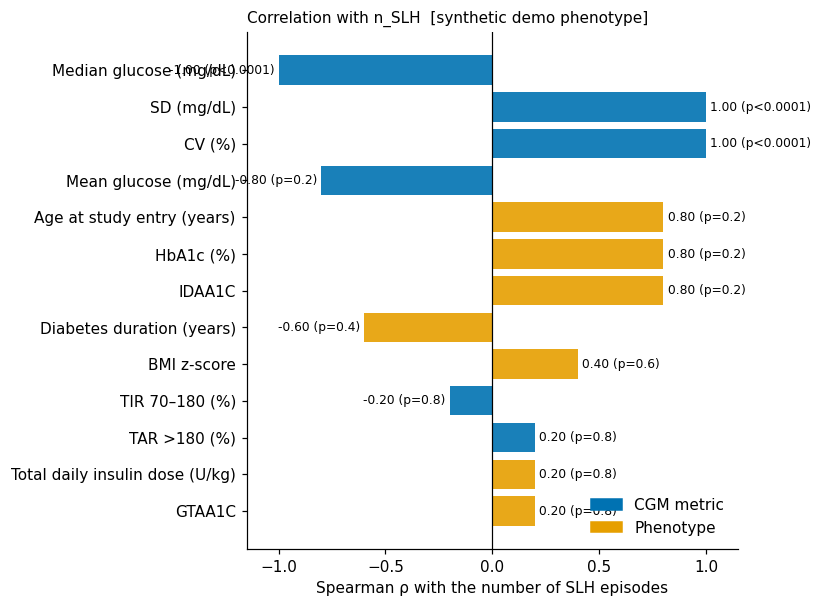

In [5]:
def format_p(p):
    return "p<0.0001" if p < 1e-4 else f"p={p:.2g}"


plot_df = spearman.dropna(subset=["rho"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 0.34 * len(plot_df) + 1.2))
bars = ax.barh(plot_df["label"], plot_df["rho"], color=[GROUP_COLOR[g] for g in plot_df["group"]], alpha=0.9)
for bar, r in zip(bars, plot_df.itertuples()):
    ax.text(r.rho + (0.02 if r.rho >= 0 else -0.02), bar.get_y() + bar.get_height() / 2,
            f"{r.rho:.2f} ({format_p(r.p)})", va="center", ha="left" if r.rho >= 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(-1.15, 1.15)
ax.set_xlabel(f"Spearman ρ with the number of SLH episodes")
ax.set_title(f"Correlation with n_SLH{DEMO_TAG}", loc="left", fontsize=10)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=g) for g, c in GROUP_COLOR.items()],
          frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Correlation matrix.** Many variables are collinear (for example HbA1c, IDAA1C and GTAA1C, or mean glucose and TAR), so the matrix shows which signals are redundant.

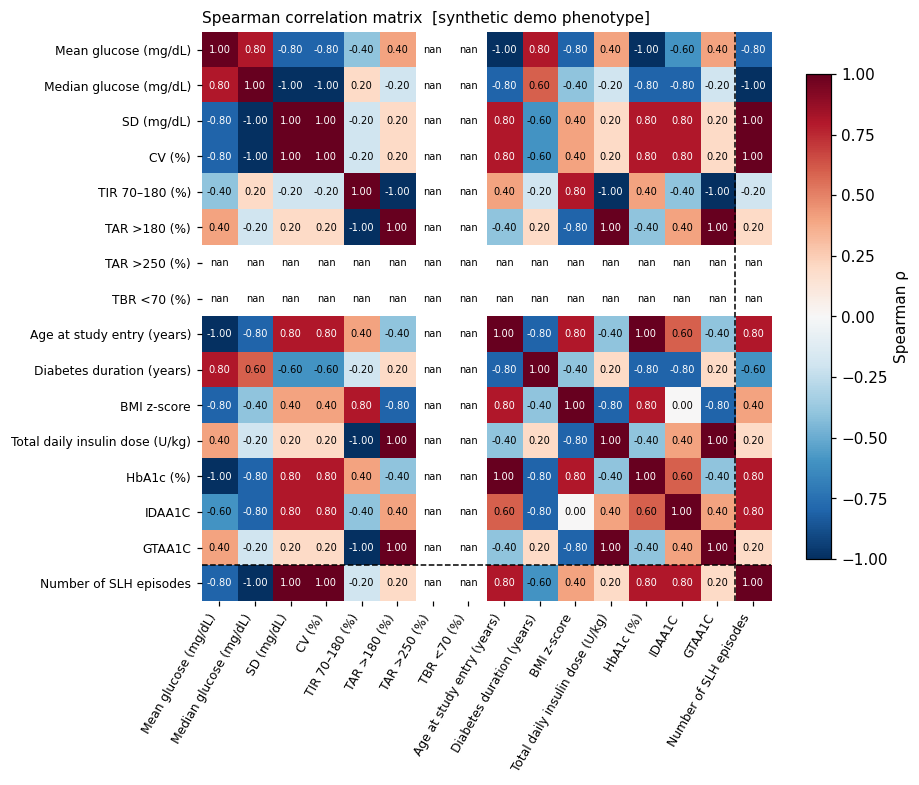

In [6]:
cols = [c for c in continuous if data[c].notna().sum() > 2] + [RESPONSE]
labels = [CONTINUOUS_LABELS.get(c, RESPONSE_LABEL) for c in cols]

rho_matrix = data[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(rho_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(labels, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = rho_matrix.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "black")
ax.axhline(len(cols) - 1.5, color="k", ls="--", lw=1); ax.axvline(len(cols) - 1.5, color="k", ls="--", lw=1)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title(f"Spearman correlation matrix{DEMO_TAG}", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Mutual information with n_SLH

Mutual information (MI) measures any statistical dependence, linear or not, between a variable and n_SLH (in nats; 0 = independent).

- **Continuous variables** — `mutual_info_regression` on the variable.
- **Categorical variables** — the MI of each dummy-coded level is summed.
- **Permutation test** — MI is biased upwards in small samples, so each value is compared with the MI obtained after shuffling
  n_SLH `N_PERMUTATIONS` times; `p` is the share of shuffles with an MI at least as large.

In [7]:
def mutual_information(X, y, seed=RNG_SEED):
    """Sum of MI over the columns of X (one column for a continuous variable, one per level for dummies)."""
    k = min(3, len(y) - 1)
    return float(mutual_info_regression(X, y, n_neighbors=k, random_state=seed).sum())


def mi_with_permutation_test(X, y, n_perm=N_PERMUTATIONS, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    observed = mutual_information(X, y, seed)
    null = np.array([mutual_information(X, rng.permutation(y), seed) for _ in range(n_perm)])
    return observed, float((1 + (null >= observed).sum()) / (1 + n_perm)), float(null.mean())


rows = []
for col, label in CONTINUOUS_LABELS.items():
    sub = data[[col, RESPONSE]].dropna()
    if len(sub) < 5:
        continue
    mi, p, null_mean = mi_with_permutation_test(sub[[col]].to_numpy(), sub[RESPONSE].to_numpy())
    rows.append({"label": label, "MI": mi, "p_perm": p, "MI_null_mean": null_mean, "n": len(sub),
                 "group": "CGM metric" if col in CGM_LABELS else "Phenotype (continuous)"})

for col, label in PHENO_CATEGORICAL_LABELS.items():
    sub = data[[col, RESPONSE]].dropna()
    if len(sub) < 5 or sub[col].nunique() < 2:
        continue
    dummies = pd.get_dummies(sub[col]).astype(float)
    mi, p, null_mean = mi_with_permutation_test(dummies.to_numpy(), sub[RESPONSE].to_numpy())
    rows.append({"label": label, "MI": mi, "p_perm": p, "MI_null_mean": null_mean, "n": len(sub),
                 "group": "Phenotype (categorical)"})

mi_table = pd.DataFrame(rows, columns=["label", "MI", "p_perm", "MI_null_mean", "n", "group"])
mi_table = mi_table.sort_values("MI", ascending=False).reset_index(drop=True)
if mi_table.empty:
    print("Fewer than 5 patients with complete data: mutual information is not computed.")
mi_table.round(3)

Fewer than 5 patients with complete data: mutual information is not computed.


,label,MI,p_perm,MI_null_mean,n,group


In [8]:
MI_COLORS = {"CGM metric": WONG_COLORS["blue"], "Phenotype (continuous)": WONG_COLORS["orange"],
             "Phenotype (categorical)": WONG_COLORS["reddish_purple"]}

plot_df = mi_table.iloc[::-1]
if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(7.5, 0.34 * len(plot_df) + 1.2))
    bars = ax.barh(plot_df["label"], plot_df["MI"], color=[MI_COLORS[g] for g in plot_df["group"]], alpha=0.9)
    ax.scatter(plot_df["MI_null_mean"], bars.patches and [b.get_y() + b.get_height() / 2 for b in bars],
               marker="|", s=90, color="k", zorder=4, label="mean MI after shuffling n_SLH")
    for bar, r in zip(bars, plot_df.itertuples()):
        ax.text(max(r.MI, r.MI_null_mean) + 0.005, bar.get_y() + bar.get_height() / 2,
                f"{r.MI:.3f} ({format_p(r.p_perm)})", va="center", fontsize=8)

    ax.set_xlim(0, plot_df["MI"].max() * 1.35 if len(plot_df) else 1)
    ax.set_xlabel(f"Mutual information with the number of SLH episodes (nats)")
    ax.set_title(f"Mutual information with n_SLH{DEMO_TAG}", loc="left", fontsize=10)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=g) for g, c in MI_COLORS.items()]
    handles.append(plt.Line2D([], [], marker="|", ls="", color="k", label="shuffled-n_SLH mean"))
    ax.legend(handles=handles, frameon=False, loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

**Reading the two measures together.** A variable with a high |ρ| and a high MI has a monotonic association with n_SLH.
A variable with a high MI but a low |ρ| is related in a non-monotonic way (for example a U-shaped relationship).
A small MI close to its shuffled mean is indistinguishable from noise.

In [9]:
comparison = spearman.set_index("label")[["rho", "p"]].join(
    mi_table.set_index("label")[["MI", "p_perm"]], how="outer")
comparison["|rho|"] = comparison["rho"].abs()
comparison.sort_values("MI", ascending=False).round(3)

,rho,p,MI,p_perm,|rho|
label,,,,,
Age at study entry (years),0.8,0.2,NaN,NaN,0.8
BMI z-score,0.4,0.6,NaN,NaN,0.4
CV (%),1.0,0.0,NaN,NaN,1.0
Diabetes duration (years),-0.6,0.4,NaN,NaN,0.6
GTAA1C,0.2,0.8,NaN,NaN,0.2
HbA1c (%),0.8,0.2,NaN,NaN,0.8
IDAA1C,0.8,0.2,NaN,NaN,0.8
Mean glucose (mg/dL),-0.8,0.2,NaN,NaN,0.8
Median glucose (mg/dL),-1.0,0.0,NaN,NaN,1.0


## 5. n_SLH by categorical phenotype variable

Distribution of n_SLH in each level, tested with Mann–Whitney (two levels) or Kruskal–Wallis (more levels).

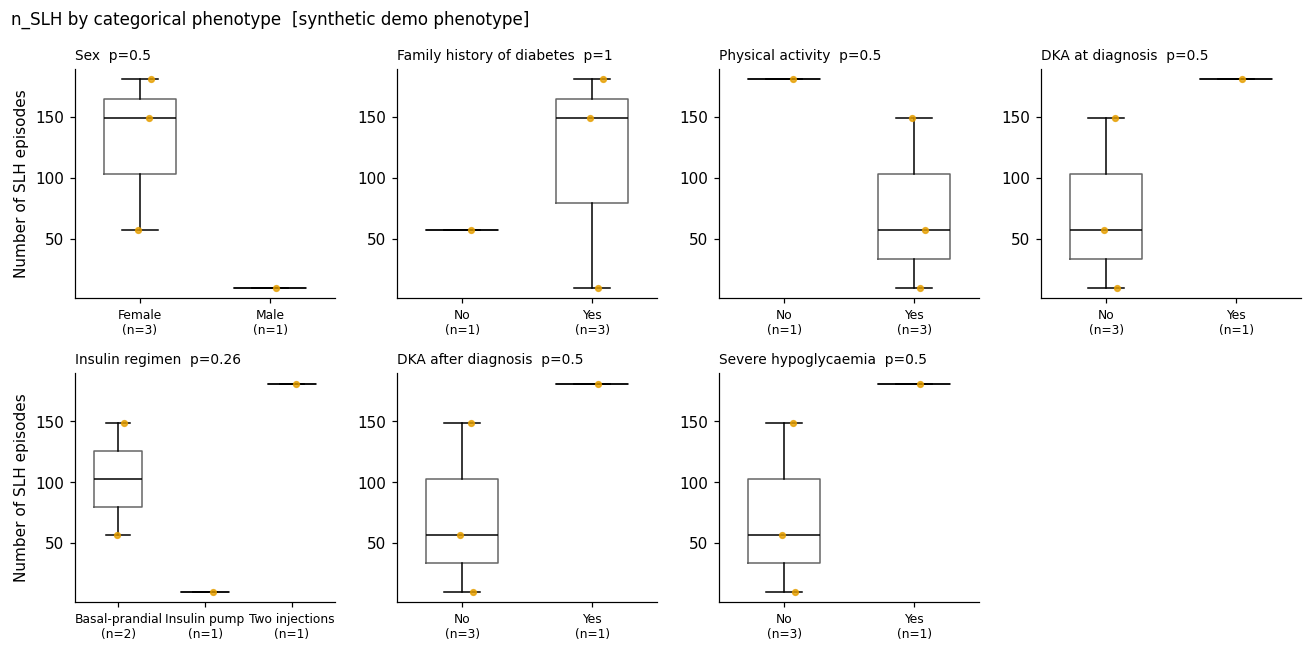

,variable,test,p,levels
0,Sex,Mann–Whitney,0.5000,"Female (n=3), Male (n=1)"
1,Family history of diabetes,Mann–Whitney,1.0000,"No (n=1), Yes (n=3)"
2,Physical activity,Mann–Whitney,0.5000,"No (n=1), Yes (n=3)"
3,DKA at diagnosis,Mann–Whitney,0.5000,"No (n=3), Yes (n=1)"
4,Insulin regimen,Kruskal–Wallis,0.2592,"Basal-prandial (n=2), Insulin pump (n=1), Two ..."
5,DKA after diagnosis,Mann–Whitney,0.5000,"No (n=3), Yes (n=1)"
6,Severe hypoglycaemia,Mann–Whitney,0.5000,"No (n=3), Yes (n=1)"


In [10]:
cat_cols = [c for c in PHENO_CATEGORICAL_LABELS if data[c].nunique() >= 2]

test_rows = []
n_cols = 4
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), squeeze=False)

for ax, col in zip(axes.ravel(), cat_cols):
    levels = sorted(data[col].dropna().unique())
    groups = [data.loc[data[col] == lv, RESPONSE].to_numpy() for lv in levels]
    rng = np.random.default_rng(RNG_SEED)

    ax.boxplot(groups, positions=range(len(levels)), widths=0.55, showfliers=False,
               medianprops=dict(color="k"), boxprops=dict(color="0.4"))
    for i, g in enumerate(groups):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(g)), g, s=14, color=WONG_COLORS["orange"], alpha=0.8, zorder=3)

    usable = [g for g in groups if len(g) > 0]
    if len(usable) >= 2:
        test = "Mann–Whitney" if len(usable) == 2 else "Kruskal–Wallis"
        stat, p = (stats.mannwhitneyu(*usable) if len(usable) == 2 else stats.kruskal(*usable))
    else:
        test, p = "–", np.nan
    test_rows.append({"variable": PHENO_CATEGORICAL_LABELS[col], "test": test, "p": p,
                      "levels": ", ".join(f"{lv} (n={len(g)})" for lv, g in zip(levels, groups))})

    ax.set_xticks(range(len(levels))); ax.set_xticklabels([f"{lv}\n(n={len(g)})" for lv, g in zip(levels, groups)], fontsize=8)
    ax.set_title(f"{PHENO_CATEGORICAL_LABELS[col]}  {format_p(p) if not np.isnan(p) else ''}", fontsize=9, loc="left")
    ax.set_ylabel(RESPONSE_LABEL if ax in axes[:, 0] else "")

for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
fig.suptitle(f"n_SLH by categorical phenotype{DEMO_TAG}", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

pd.DataFrame(test_rows).round(4)

## Notes

- p values are **not adjusted** for the number of variables tested; treat them as exploratory.
- With a small cohort the permutation p for mutual information is the more reliable of the two measures,
  because it accounts for the estimator's upward bias.
- HbA1c, IDAA1C and GTAA1C are strongly collinear (IDAA1C = HbA1c + 4 × TIDD), so they should not be read as independent findings.